In [21]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torchvision
from torchvision.datasets import MNIST
import torchvision.transforms as transforms
from torch.utils.data import random_split
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.nn.functional as F

In [2]:
dataset = MNIST(root = "data/", download = True, train = True, transform = transforms.ToTensor())
datasetSize = len(dataset)
print(datasetSize)

60000


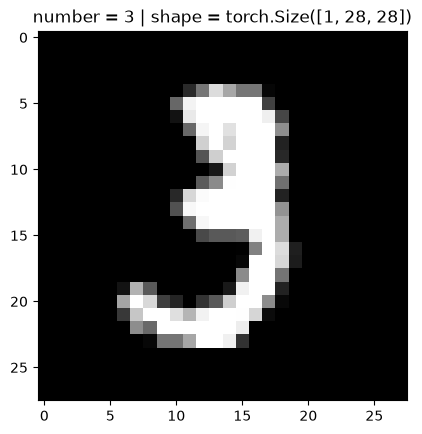

In [3]:
image, label = dataset[10]
plt.title(f"number = {label} | shape = {image.shape}")
plt.imshow(image[0], cmap="gray")

In [8]:
# splitting into validation and training
trainSize = int(datasetSize * 0.9)
validationSize = int(datasetSize - trainSize)
train_data, validation_data = random_split(dataset, [trainSize, validationSize])
print(f"train size: {len(train_data)} | validation size: {len(validation_data)}")

train size: 54000 | validation size: 6000


In [10]:
batch_size = 128
train_loader = DataLoader(train_data, batch_size, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size, shuffle=False)


In [24]:
input_size = image.shape[1] * image.shape[2]
num_classes = 10
model = nn.Linear(input_size, num_classes)
print(f"Weight = {model.weight} | bias = {model.bias}")

Weight = Parameter containing:
tensor([[ 0.0008, -0.0197, -0.0171,  ..., -0.0251,  0.0008, -0.0245],
        [ 0.0349, -0.0218, -0.0254,  ...,  0.0112, -0.0244,  0.0316],
        [-0.0172,  0.0142, -0.0012,  ..., -0.0130, -0.0121,  0.0278],
        ...,
        [ 0.0104, -0.0275, -0.0264,  ..., -0.0295, -0.0046,  0.0169],
        [-0.0015, -0.0119, -0.0125,  ..., -0.0292, -0.0134, -0.0217],
        [ 0.0293, -0.0186,  0.0327,  ..., -0.0061, -0.0086,  0.0326]],
       requires_grad=True) | bias = Parameter containing:
tensor([-0.0007, -0.0095, -0.0317,  0.0150, -0.0311,  0.0116, -0.0125,  0.0095,
        -0.0169, -0.0110], requires_grad=True)


In [25]:
def forward(model: nn.Linear, input, input_size):
    input = input.reshape(-1, input_size)
    return model(input)

In [26]:
for images, labels in train_loader:
    outputs = forward(model, images, input_size)
    break

print(f"output shape = {outputs.shape}")
print(f"Sample outputs \n = {outputs[:2].data}")


output shape = torch.Size([128, 10])
Sample outputs 
 = tensor([[ 0.0889, -0.0359, -0.1161,  0.3509, -0.3004, -0.0389, -0.1311, -0.0979,
         -0.0475, -0.0582],
        [ 0.1046,  0.0754, -0.1527, -0.0401,  0.2097, -0.2106, -0.0537, -0.1474,
          0.0361, -0.0814]])


In [39]:
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, dim = 1)
    return(torch.tensor(torch.sum(preds == labels).item()/ len(preds)))

In [40]:
def validation_step(model, batch):
	images, labels = batch
	inp = images.reshape(-1, input_size)
	out = model(inp)
	loss = F.cross_entropy(out, labels)
	acc = accuracy(out, labels)
	return({'val_loss':loss, 'val_acc': acc})

In [45]:
def train(model, epochs, learning_rate, train_loader, validation_loader, opt_func = torch.optim.SGD):
    history = []
    optimizer = opt_func(model.parameters(), learning_rate)
    input_size = 28 * 28
    
    for e in range(epochs):
        for batch in train_loader:
            images, labels = batch
            inp = images.reshape(-1, input_size)
            out = model(inp)
            loss = F.cross_entropy(out, labels)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        # Aggregate validation metrics across all validation batches
        results = [validation_step(model, batch) for batch in validation_loader]
        val_loss = torch.stack([x['val_loss'] for x in results]).mean().item()
        val_acc = torch.stack([x['val_acc'] for x in results]).mean().item()

        epoch_result = {'val_loss': val_loss, 'val_acc': val_acc}
        print("Epoch [{}], val_loss: {:.4f}, val_acc: {:.4f}".format(e, epoch_result['val_loss'], epoch_result['val_acc']))
        history.append(epoch_result)

    return history

In [46]:
hist1 = train(model, 5, 0.001, train_loader, validation_loader)
hist2 = train(model, 5, 0.001, train_loader, validation_loader)
hist3 = train(model, 5, 0.001, train_loader, validation_loader)
hist4 = train(model, 5, 0.001, train_loader, validation_loader)
hist5 = train(model, 5, 0.001, train_loader, validation_loader)


Epoch [0], val_loss: 1.0927, val_acc: 0.8116
Epoch [1], val_loss: 1.0202, val_acc: 0.8177
Epoch [2], val_loss: 0.9611, val_acc: 0.8262
Epoch [3], val_loss: 0.9121, val_acc: 0.8312
Epoch [4], val_loss: 0.8710, val_acc: 0.8350
Epoch [0], val_loss: 0.8359, val_acc: 0.8370
Epoch [1], val_loss: 0.8055, val_acc: 0.8425
Epoch [2], val_loss: 0.7791, val_acc: 0.8461
Epoch [3], val_loss: 0.7556, val_acc: 0.8493
Epoch [4], val_loss: 0.7349, val_acc: 0.8513
Epoch [0], val_loss: 0.7162, val_acc: 0.8526
Epoch [1], val_loss: 0.6994, val_acc: 0.8557
Epoch [2], val_loss: 0.6842, val_acc: 0.8577
Epoch [3], val_loss: 0.6703, val_acc: 0.8591
Epoch [4], val_loss: 0.6576, val_acc: 0.8609
Epoch [0], val_loss: 0.6459, val_acc: 0.8622
Epoch [1], val_loss: 0.6352, val_acc: 0.8627
Epoch [2], val_loss: 0.6252, val_acc: 0.8636
Epoch [3], val_loss: 0.6159, val_acc: 0.8647
Epoch [4], val_loss: 0.6072, val_acc: 0.8659
Epoch [0], val_loss: 0.5991, val_acc: 0.8666
Epoch [1], val_loss: 0.5915, val_acc: 0.8664
Epoch [2],

Text(0.5, 1.0, 'Accuracy Vs. No. of epochs')

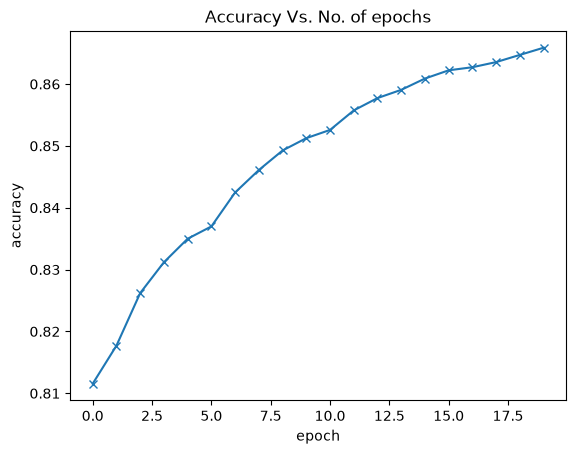

In [47]:
history = hist1 + hist2 + hist3 + hist4
accuracies = [result['val_acc'] for result in history]
plt.plot(accuracies, '-x')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Accuracy Vs. No. of epochs')

In [48]:
test_dataset = MNIST(root = 'data/', train = False, transform = transforms.ToTensor())

shape:  torch.Size([1, 28, 28])
Label:  7


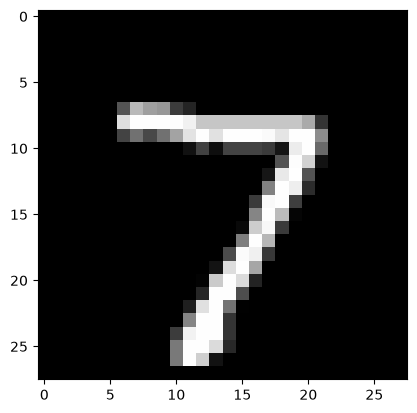

In [49]:
img, label = test_dataset[0]
plt.imshow(img[0], cmap = 'gray')
print("shape: ", img.shape)
print('Label: ', label)

In [54]:
def predict(img, model):
    x = img.unsqueeze(0)
    inp = x.reshape(-1, 28*28)
    y = model(inp)
    _, pred = torch.max(y, dim=1)
    return pred[0].item()

Label: 7 , Predicted : 7


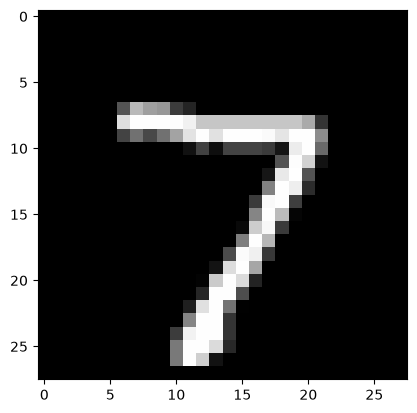

In [55]:
img, label = test_dataset[0]
plt.imshow(img[0], cmap = 'gray')
print('Label:', label, ', Predicted :', predict(img, model))

Label: 6 , Predicted : 6


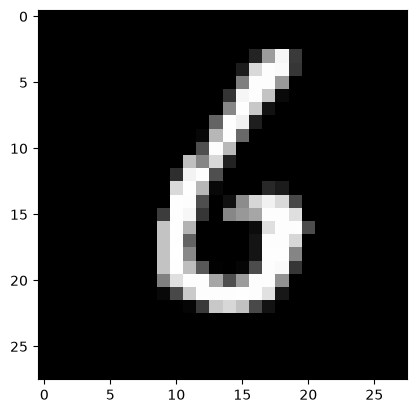

In [56]:
img, label = test_dataset[50]
plt.imshow(img[0], cmap = 'gray')
print('Label:', label, ', Predicted :', predict(img, model))

Label: 6 , Predicted : 6


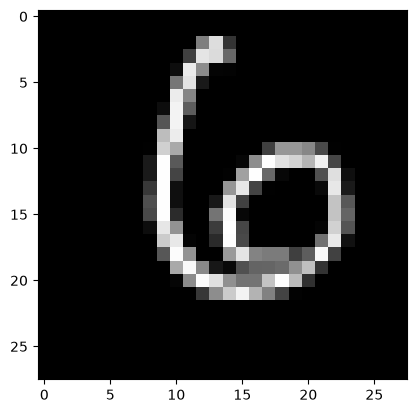

In [57]:
img, label = test_dataset[100]
plt.imshow(img[0], cmap = 'gray')
print('Label:', label, ', Predicted :', predict(img, model))

Label: 9 , Predicted : 7


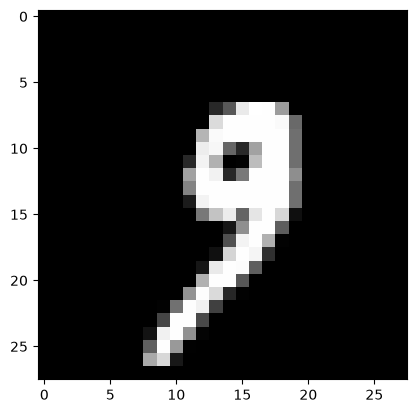

In [58]:
img, label = test_dataset[1000]
plt.imshow(img[0], cmap = 'gray')
print('Label:', label, ', Predicted :', predict(img, model))